<a href="https://colab.research.google.com/github/PRIYA-P14/Software_Quality_Insights-CH28/blob/main/CH28_Software_Quality_Insight.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

modules = pd.read_csv("/content/modules.csv")
metrics = pd.read_csv("/content/metrics.csv")
defects = pd.read_csv("/content/defects.csv")
commits = pd.read_csv("/content/commits.csv")
releases = pd.read_csv("/content/releases.csv")

datasets = {
    "modules": modules,
    "metrics": metrics,
    "defects": defects,
    "commits": commits,
    "releases": releases
}

for name, df in datasets.items():
    print("\nDataset:", name)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head())



Dataset: modules
Shape: (500, 5)
Columns: ['module', 'component', 'language', 'size', 'release']


,module,component,language,size,release
0,MOD001,Reporting,Java,14820,v1.0
1,MOD001,Reporting,Java,14820,v2.0
2,MOD001,Reporting,Java,14820,v3.0
3,MOD001,Reporting,Java,14820,v4.0
4,MOD001,Reporting,Java,14820,v5.0



Dataset: metrics
Shape: (500, 6)
Columns: ['module', 'release', 'complexity', 'coupling', 'churn', 'test_coverage']


,module,release,complexity,coupling,churn,test_coverage
0,MOD001,v1.0,65,12.0,150,85.18
1,MOD001,v2.0,56,8.0,151,90.53
2,MOD001,v3.0,57,7.0,74,94.13
3,MOD001,v4.0,55,11.0,121,79.53
4,MOD001,v5.0,53,8.0,193,82.59



Dataset: defects
Shape: (500, 4)
Columns: ['module', 'release', 'defect_count', 'severity']


,module,release,defect_count,severity
0,MOD001,v1.0,8.0,Low
1,MOD001,v2.0,0.0,Low
2,MOD001,v3.0,8.0,Medium
3,MOD001,v4.0,2.0,Low
4,MOD001,v5.0,4.0,High



Dataset: commits
Shape: (500, 5)
Columns: ['module', 'release', 'commit_count', 'contributors', 'changed_lines']


,module,release,commit_count,contributors,changed_lines
0,MOD001,v1.0,15,6.0,142
1,MOD001,v2.0,13,1.0,170
2,MOD001,v3.0,2,1.0,60
3,MOD001,v4.0,9,9.0,110
4,MOD001,v5.0,9,7.0,204



Dataset: releases
Shape: (500, 4)
Columns: ['module', 'release', 'version', 'release_date']


,module,release,version,release_date
0,MOD001,v1.0,v1.0,2024-01-15
1,MOD001,v2.0,v2.0,2024-04-14
2,MOD001,v3.0,v3.0,2024-07-13
3,MOD001,v4.0,v4.0,2024-10-11
4,MOD001,v5.0,v5.0,2025-01-09


In [ ]:
print(releases["release_date"].head())
print(releases["release_date"].dtype)

0    2024-01-15
1    2024-04-14
2    2024-07-13
3    2024-10-11
4    2025-01-09
Name: release_date, dtype: object
object


In [ ]:

releases["release_date"] = pd.to_datetime(
    releases["release_date"],
    errors="coerce"
)

print(releases["release_date"].head())
print("\nData type:", releases["release_date"].dtype)


0   2024-01-15
1   2024-04-14
2   2024-07-13
3   2024-10-11
4   2025-01-09
Name: release_date, dtype: datetime64[ns]

Data type: datetime64[ns]


ind missing values in all five datasets

In [ ]:

for name, df in datasets.items():
    print("\nDataset:", name)
    print(df.isnull().sum())



Dataset: modules
module       0
component    0
language     0
size         0
release      0
dtype: int64

Dataset: metrics
module           0
release          0
complexity       0
coupling         2
churn            0
test_coverage    5
dtype: int64

Dataset: defects
module          0
release         0
defect_count    3
severity        0
dtype: int64

Dataset: commits
module           0
release          0
commit_count     0
contributors     3
changed_lines    0
dtype: int64

Dataset: releases
module          0
release         0
version         0
release_date    0
dtype: int64


Check duplicate records

In [ ]:

for name, df in datasets.items():
    print("\nDataset:", name)
    print("Duplicate rows:", df.duplicated().sum())



Dataset: modules
Duplicate rows: 0

Dataset: metrics
Duplicate rows: 0

Dataset: defects
Duplicate rows: 0

Dataset: commits
Duplicate rows: 0

Dataset: releases
Duplicate rows: 0


Check data types

In [ ]:

for name, df in datasets.items():
    print("\nDataset:", name)
    print(df.dtypes)



Dataset: modules
module       object
component    object
language     object
size          int64
release      object
dtype: object

Dataset: metrics
module            object
release           object
complexity         int64
coupling         float64
churn              int64
test_coverage    float64
dtype: object

Dataset: defects
module           object
release          object
defect_count    float64
severity         object
dtype: object

Dataset: commits
module            object
release           object
commit_count       int64
contributors     float64
changed_lines      int64
dtype: object

Dataset: releases
module                  object
release                 object
version                 object
release_date    datetime64[ns]
dtype: object


Check unusual numerical values

In [ ]:

for name, df in datasets.items():
    print("\n==========", name, "==========")
    print(df.describe(include="all"))



========== modules ==========
        module      component    language          size release
count      500            500         500    500.000000     500
unique     101              6           4           NaN       5
top     MOD001  Notifications  JavaScript           NaN    v1.0
freq         5            125         145           NaN     100
mean       NaN            NaN         NaN  12044.000000     NaN
std        NaN            NaN         NaN   6868.117181     NaN
min        NaN            NaN         NaN    629.000000     NaN
25%        NaN            NaN         NaN   6490.000000     NaN
50%        NaN            NaN         NaN  11020.000000     NaN
75%        NaN            NaN         NaN  18147.750000     NaN
max        NaN            NaN         NaN  24992.000000     NaN

========== metrics ==========
        module release  complexity    coupling       churn  test_coverage
count      500     500  500.000000  498.000000  500.000000     495.000000
unique     101       5

Find unusual values

In [ ]:

print("Unusual complexity values:")
display(metrics[metrics["complexity"] > 150])

print("Unusual changed-line values:")
display(commits[commits["changed_lines"] > 5000])


Unusual complexity values:


,module,release,complexity,coupling,churn,test_coverage
42,MOD009,v3.0,999,5.0,419,85.48


Unusual changed-line values:


,module,release,commit_count,contributors,changed_lines
67,MOD014,v3.0,18,4.0,25000


Check inconsistent module names

In [ ]:

for name, df in datasets.items():
    if "module" in df.columns:
        inconsistent = df[
            df["module"] != df["module"].str.strip().str.upper()
        ]

        print("\nDataset:", name)
        print("Inconsistent module names:", len(inconsistent))

        if not inconsistent.empty:
            display(inconsistent[["module"]].drop_duplicates())



Dataset: modules
Inconsistent module names: 1


,module
33,mod007



Dataset: metrics
Inconsistent module names: 1


,module
88,mod089



Dataset: defects
Inconsistent module names: 0

Dataset: commits
Inconsistent module names: 0

Dataset: releases
Inconsistent module names: 0


Check duplicate module-release combinations

In [ ]:

for name, df in datasets.items():
    if "module" in df.columns and "release" in df.columns:
        duplicate_keys = df.duplicated(
            subset=["module", "release"],
            keep=False
        )

        print("\nDataset:", name)
        print("Duplicate module-release rows:", duplicate_keys.sum())

        if duplicate_keys.any():
            display(
                df.loc[duplicate_keys]
                .sort_values(["module", "release"])
            )



Dataset: modules
Duplicate module-release rows: 0

Dataset: metrics
Duplicate module-release rows: 0

Dataset: defects
Duplicate module-release rows: 0

Dataset: commits
Duplicate module-release rows: 0

Dataset: releases
Duplicate module-release rows: 0


Clean inconsistent module names

In [ ]:

for name, df in datasets.items():
    if "module" in df.columns:
        df["module"] = (
            df["module"]
            .str.strip()
            .str.upper()
        )

print("Module names standardized successfully!")

for name, df in datasets.items():
    if "module" in df.columns:
        print(
            name,
            "unique modules:",
            df["module"].nunique()
        )


Module names standardized successfully!
modules unique modules: 100
metrics unique modules: 100
defects unique modules: 101
commits unique modules: 100
releases unique modules: 100


Investigate the unmatched module

In [ ]:

module_names = set(modules["module"])
defect_module_names = set(defects["module"])

unmatched_modules = defect_module_names - module_names

print("Unmatched modules:", unmatched_modules)


Unmatched modules: {'UNKNOWN_MOD'}


Inspect the unmatched defect record

In [ ]:

unmatched_records = defects[
    ~defects["module"].isin(modules["module"])
]

display(unmatched_records)


,module,release,defect_count,severity
120,UNKNOWN_MOD,v1.0,6.0,Low


Handle missing values in metrics

In [ ]:

print("Missing values before cleaning:")
print(metrics[["coupling", "test_coverage"]].isnull().sum())

metrics["coupling"] = metrics["coupling"].fillna(
    metrics["coupling"].median()
)

metrics["test_coverage"] = metrics["test_coverage"].fillna(
    metrics["test_coverage"].median()
)

print("\nMissing values after cleaning:")
print(metrics[["coupling", "test_coverage"]].isnull().sum())


Missing values before cleaning:
coupling         2
test_coverage    5
dtype: int64

Missing values after cleaning:
coupling         0
test_coverage    0
dtype: int64


Handle missing values in defects.csv

In [ ]:

print("Missing values before cleaning:")
print(defects["defect_count"].isnull().sum())

median_defects = defects["defect_count"].median()

defects["defect_count"] = defects["defect_count"].fillna(
    median_defects
)

print("\nMedian defect count:", median_defects)

print("\nMissing values after cleaning:")
print(defects["defect_count"].isnull().sum())


Missing values before cleaning:
3

Median defect count: 6.0

Missing values after cleaning:
0


Handle missing values in commits.csv

In [ ]:

print("Missing values before cleaning:")
print(commits["contributors"].isnull().sum())

median_contributors = commits["contributors"].median()

commits["contributors"] = commits["contributors"].fillna(
    median_contributors
)

print("\nMedian contributors:", median_contributors)

print("\nMissing values after cleaning:")
print(commits["contributors"].isnull().sum())


Missing values before cleaning:
3

Median contributors: 5.0

Missing values after cleaning:
0


Verify missing values in all five datasets

In [ ]:

for name, df in datasets.items():
    print("\nDataset:", name)
    print("Total missing values:", df.isnull().sum().sum())
    print(df.isnull().sum())



Dataset: modules
Total missing values: 0
module       0
component    0
language     0
size         0
release      0
dtype: int64

Dataset: metrics
Total missing values: 0
module           0
release          0
complexity       0
coupling         0
churn            0
test_coverage    0
dtype: int64

Dataset: defects
Total missing values: 0
module          0
release         0
defect_count    0
severity        0
dtype: int64

Dataset: commits
Total missing values: 0
module           0
release          0
commit_count     0
contributors     0
changed_lines    0
dtype: int64

Dataset: releases
Total missing values: 0
module          0
release         0
version         0
release_date    0
dtype: int64


Handle unusual numerical values

In [ ]:

metrics["complexity_outlier"] = metrics["complexity"] > 150

commits["changed_lines_outlier"] = commits["changed_lines"] > 5000

print("Unusual complexity records:")
display(
    metrics[metrics["complexity_outlier"]]
)

print("Unusual changed-line records:")
display(
    commits[commits["changed_lines_outlier"]]
)


Unusual complexity records:


,module,release,complexity,coupling,churn,test_coverage,complexity_outlier
42,MOD009,v3.0,999,5.0,419,85.48,True


Unusual changed-line records:


,module,release,commit_count,contributors,changed_lines,changed_lines_outlier
67,MOD014,v3.0,18,4.0,25000,True


Check the row counts before merging

In [ ]:

for name, df in datasets.items():
    print(name, ":", df.shape[0], "rows")


modules : 500 rows
metrics : 500 rows
defects : 500 rows
commits : 500 rows
releases : 500 rows


Check matching module-release keys

In [ ]:

key_datasets = {
    "modules": modules,
    "metrics": metrics,
    "defects": defects,
    "commits": commits,
    "releases": releases
}

reference_keys = set(
    zip(modules["module"], modules["release"])
)

for name, df in key_datasets.items():
    current_keys = set(zip(df["module"], df["release"]))

    missing_keys = reference_keys - current_keys
    extra_keys = current_keys - reference_keys

    print("\nDataset:", name)
    print("Unique module-release keys:", len(current_keys))
    print("Keys missing compared with modules:", len(missing_keys))
    print("Extra keys compared with modules:", len(extra_keys))

    if extra_keys:
        print("Example extra keys:", list(extra_keys)[:5])



Dataset: modules
Unique module-release keys: 500
Keys missing compared with modules: 0
Extra keys compared with modules: 0

Dataset: metrics
Unique module-release keys: 499
Keys missing compared with modules: 1
Extra keys compared with modules: 0

Dataset: defects
Unique module-release keys: 500
Keys missing compared with modules: 1
Extra keys compared with modules: 1
Example extra keys: [('UNKNOWN_MOD', 'v1.0')]

Dataset: commits
Unique module-release keys: 500
Keys missing compared with modules: 0
Extra keys compared with modules: 0

Dataset: releases
Unique module-release keys: 500
Keys missing compared with modules: 0
Extra keys compared with modules: 0


Find the exact missing keys

In [ ]:

reference_keys = set(
    zip(modules["module"], modules["release"])
)

for name, df in {
    "metrics": metrics,
    "defects": defects
}.items():

    current_keys = set(zip(df["module"], df["release"]))
    missing_keys = reference_keys - current_keys

    print("\nDataset:", name)
    print("Missing module-release keys:", missing_keys)



Dataset: metrics
Missing module-release keys: {('MOD018', 'v4.0')}

Dataset: defects
Missing module-release keys: {('MOD025', 'v1.0')}


Find the duplicate keys in metrics

In [ ]:

duplicate_keys = metrics[
    metrics.duplicated(
        subset=["module", "release"],
        keep=False
    )
].sort_values(["module", "release"])

print("Number of rows involved in duplicate keys:",
      len(duplicate_keys))

display(duplicate_keys)


Number of rows involved in duplicate keys: 2


,module,release,complexity,coupling,churn,test_coverage,complexity_outlier
88,MOD089,v4.0,20,19.0,312,95.88,False
443,MOD089,v4.0,41,28.0,13,33.70,False


Inspect the original records

In [ ]:

display(
    metrics.loc[[88, 443]]
)


,module,release,complexity,coupling,churn,test_coverage,complexity_outlier
88,MOD089,v4.0,20,19.0,312,95.88,False
443,MOD089,v4.0,41,28.0,13,33.70,False


Create a merge-ready metrics dataset

In [ ]:

metrics_merge = metrics.copy()

metrics_merge = (
    metrics_merge
    .groupby(["module", "release"], as_index=False)
    .agg({
        "complexity": "median",
        "coupling": "median",
        "churn": "median",
        "test_coverage": "median",
        "complexity_outlier": "max"
    })
)

print("Original metrics rows:", len(metrics))
print("Merge-ready metrics rows:", len(metrics_merge))

print(
    "Duplicate keys remaining:",
    metrics_merge.duplicated(
        subset=["module", "release"]
    ).sum()
)

display(
    metrics_merge[
        (metrics_merge["module"] == "MOD089") &
        (metrics_merge["release"] == "v4.0")
    ]
)


Original metrics rows: 500
Merge-ready metrics rows: 499
Duplicate keys remaining: 0


,module,release,complexity,coupling,churn,test_coverage,complexity_outlier
442,MOD089,v4.0,30.5,23.5,162.5,64.79,False


Merge the five datasets

In [ ]:

# Merge module information with metrics
combined = modules.merge(
    metrics_merge,
    on=["module", "release"],
    how="left",
    validate="one_to_one"
)

# Merge defect information
combined = combined.merge(
    defects,
    on=["module", "release"],
    how="left",
    validate="one_to_one"
)

# Merge commit information
combined = combined.merge(
    commits,
    on=["module", "release"],
    how="left",
    validate="one_to_one"
)

# Add release dates
combined = combined.merge(
    releases[["module", "release", "release_date"]],
    on=["module", "release"],
    how="left",
    validate="one_to_one"
)

print("Combined dataset shape:", combined.shape)
print("Total rows:", len(combined))
print("\nFirst five rows:")
display(combined.head())


Combined dataset shape: (500, 17)
Total rows: 500

First five rows:


,module,component,language,size,release,complexity,coupling,churn,test_coverage,complexity_outlier,defect_count,severity,commit_count,contributors,changed_lines,changed_lines_outlier,release_date
0,MOD001,Reporting,Java,14820,v1.0,65.0,12.0,150.0,85.18,False,8.0,Low,15,6.0,142,False,2024-01-15
1,MOD001,Reporting,Java,14820,v2.0,56.0,8.0,151.0,90.53,False,0.0,Low,13,1.0,170,False,2024-04-14
2,MOD001,Reporting,Java,14820,v3.0,57.0,7.0,74.0,94.13,False,8.0,Medium,2,1.0,60,False,2024-07-13
3,MOD001,Reporting,Java,14820,v4.0,55.0,11.0,121.0,79.53,False,2.0,Low,9,9.0,110,False,2024-10-11
4,MOD001,Reporting,Java,14820,v5.0,53.0,8.0,193.0,82.59,False,4.0,High,9,7.0,204,False,2025-01-09


Check missing values created by merging

In [ ]:

print("Missing values in combined dataset:")
print(combined.isnull().sum())

print(
    "\nTotal missing cells:",
    combined.isnull().sum().sum()
)


Missing values in combined dataset:
module                   0
component                0
language                 0
size                     0
release                  0
complexity               1
coupling                 1
churn                    1
test_coverage            1
complexity_outlier       1
defect_count             1
severity                 1
commit_count             0
contributors             0
changed_lines            0
changed_lines_outlier    0
release_date             0
dtype: int64

Total missing cells: 7


Find the row with missing values

In [ ]:

missing_rows = combined[
    combined.isnull().any(axis=1)
]

print("Rows containing missing values:", len(missing_rows))
display(missing_rows)


Rows containing missing values: 2


,module,component,language,size,release,complexity,coupling,churn,test_coverage,complexity_outlier,defect_count,severity,commit_count,contributors,changed_lines,changed_lines_outlier,release_date
88,MOD018,Reporting,Python,13130,v4.0,NaN,NaN,NaN,NaN,NaN,4.0,Medium,10,8.0,330,False,2024-10-11
120,MOD025,Inventory,Java,10718,v1.0,18.0,24.0,122.0,61.53,False,NaN,NaN,6,3.0,109,False,2024-01-15


Check the missing values by record

In [ ]:

print("Missing metrics records:")
display(
    combined.loc[
        combined["complexity"].isnull(),
        ["module", "release", "complexity", "coupling",
         "churn", "test_coverage", "defect_count"]
    ]
)

print("Missing defect records:")
display(
    combined.loc[
        combined["defect_count"].isnull(),
        ["module", "release", "complexity",
         "test_coverage", "defect_count", "severity"]
    ]
)


Missing metrics records:


,module,release,complexity,coupling,churn,test_coverage,defect_count
88,MOD018,v4.0,NaN,NaN,NaN,NaN,4.0


Missing defect records:


,module,release,complexity,test_coverage,defect_count,severity
120,MOD025,v1.0,18.0,61.53,NaN,NaN


Verify your master dataset

In [ ]:

print("Final dataset shape:", combined.shape)

print("\nDuplicate module-release keys:")
print(
    combined.duplicated(
        subset=["module", "release"]
    ).sum()
)

print("\nMissing values by column:")
print(combined.isnull().sum())

print("\nSample records:")
display(combined.head())


Final dataset shape: (500, 17)

Duplicate module-release keys:
0

Missing values by column:
module                   0
component                0
language                 0
size                     0
release                  0
complexity               1
coupling                 1
churn                    1
test_coverage            1
complexity_outlier       1
defect_count             1
severity                 1
commit_count             0
contributors             0
changed_lines            0
changed_lines_outlier    0
release_date             0
dtype: int64

Sample records:


,module,component,language,size,release,complexity,coupling,churn,test_coverage,complexity_outlier,defect_count,severity,commit_count,contributors,changed_lines,changed_lines_outlier,release_date
0,MOD001,Reporting,Java,14820,v1.0,65.0,12.0,150.0,85.18,False,8.0,Low,15,6.0,142,False,2024-01-15
1,MOD001,Reporting,Java,14820,v2.0,56.0,8.0,151.0,90.53,False,0.0,Low,13,1.0,170,False,2024-04-14
2,MOD001,Reporting,Java,14820,v3.0,57.0,7.0,74.0,94.13,False,8.0,Medium,2,1.0,60,False,2024-07-13
3,MOD001,Reporting,Java,14820,v4.0,55.0,11.0,121.0,79.53,False,2.0,Low,9,9.0,110,False,2024-10-11
4,MOD001,Reporting,Java,14820,v5.0,53.0,8.0,193.0,82.59,False,4.0,High,9,7.0,204,False,2025-01-09


Which modules have more defects?

In [ ]:

module_defects = (
    combined
    .groupby("module", as_index=False)
    .agg(
        total_defects=("defect_count", "sum"),
        releases_with_defect_data=("defect_count", "count")
    )
    .sort_values("total_defects", ascending=False)
)

print("Top 10 modules by total defects:")
display(module_defects.head(10))


Top 10 modules by total defects:


,module,total_defects,releases_with_defect_data
21,MOD022,59.0,5
37,MOD038,56.0,5
84,MOD085,54.0,5
2,MOD003,54.0,5
19,MOD020,52.0,5
93,MOD094,51.0,5
39,MOD040,51.0,5
3,MOD004,51.0,5
18,MOD019,47.0,5
36,MOD037,47.0,5


Visualize defects by module

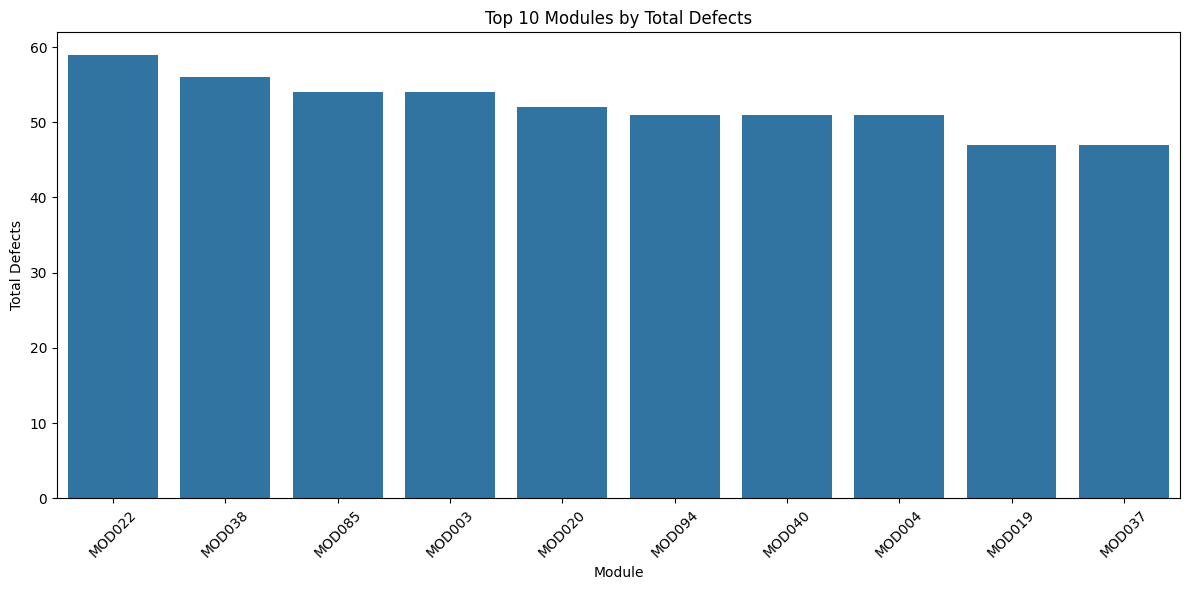

In [ ]:

plt.figure(figsize=(12, 6))

sns.barplot(
    data=module_defects.head(10),
    x="module",
    y="total_defects"
)

plt.title("Top 10 Modules by Total Defects")
plt.xlabel("Module")
plt.ylabel("Total Defects")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Code complexity vs. defects

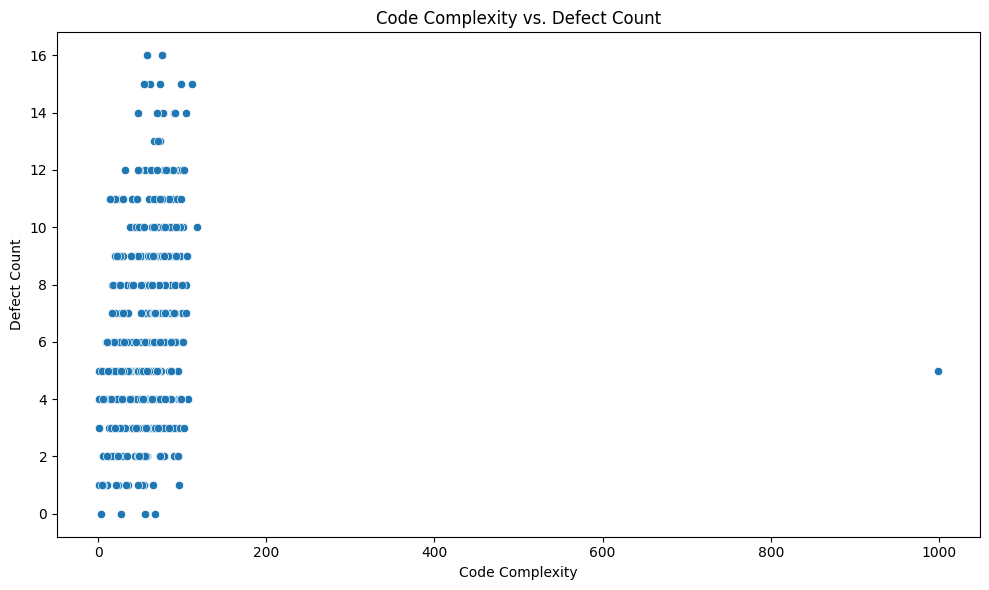

In [ ]:

# Compare code complexity with defect count
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=combined,
    x="complexity",
    y="defect_count"
)

plt.title("Code Complexity vs. Defect Count")
plt.xlabel("Code Complexity")
plt.ylabel("Defect Count")
plt.tight_layout()
plt.show()


Calculate correlation

In [ ]:

# Select rows where both values are available
complexity_data = combined[
    ["complexity", "defect_count"]
].dropna()

# Calculate Pearson correlation
correlation = complexity_data[
    "complexity"
].corr(complexity_data["defect_count"])

print("Correlation between complexity and defects:", round(correlation, 3))


Correlation between complexity and defects: 0.163


Check correlation without the extreme value

In [ ]:

# Exclude extreme complexity values for comparison
normal_complexity_data = combined[
    (combined["complexity"] <= 150) &
    (combined["complexity"].notna()) &
    (combined["defect_count"].notna())
]

correlation_without_outlier = normal_complexity_data[
    "complexity"
].corr(normal_complexity_data["defect_count"])

print(
    "Correlation before excluding outlier:",
    round(correlation, 3)
)

print(
    "Correlation after excluding outlier:",
    round(correlation_without_outlier, 3)
)


Correlation before excluding outlier: 0.163
Correlation after excluding outlier: 0.342


Analyze code churn vs. defects

Correlation between code churn and defects: 0.464


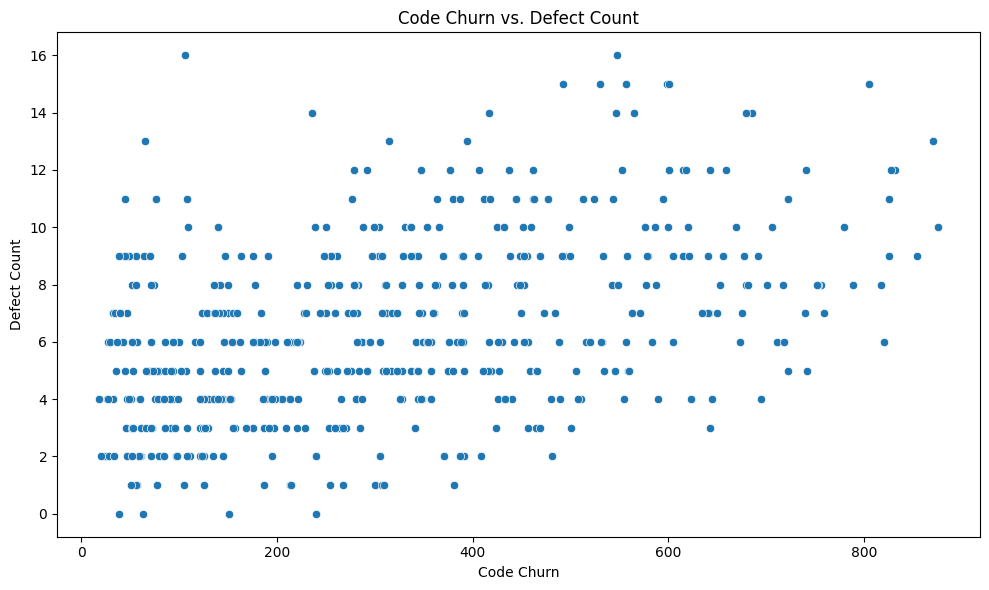

In [ ]:

# Calculate correlation between code churn and defects
churn_data = combined[
    ["churn", "defect_count"]
].dropna()

churn_correlation = churn_data["churn"].corr(
    churn_data["defect_count"]
)

print(
    "Correlation between code churn and defects:",
    round(churn_correlation, 3)
)

# Visualize the relationship
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=churn_data,
    x="churn",
    y="defect_count"
)

plt.title("Code Churn vs. Defect Count")
plt.xlabel("Code Churn")
plt.ylabel("Defect Count")
plt.tight_layout()
plt.show()


Test coverage vs. defects

Correlation between test coverage and defects: -0.208


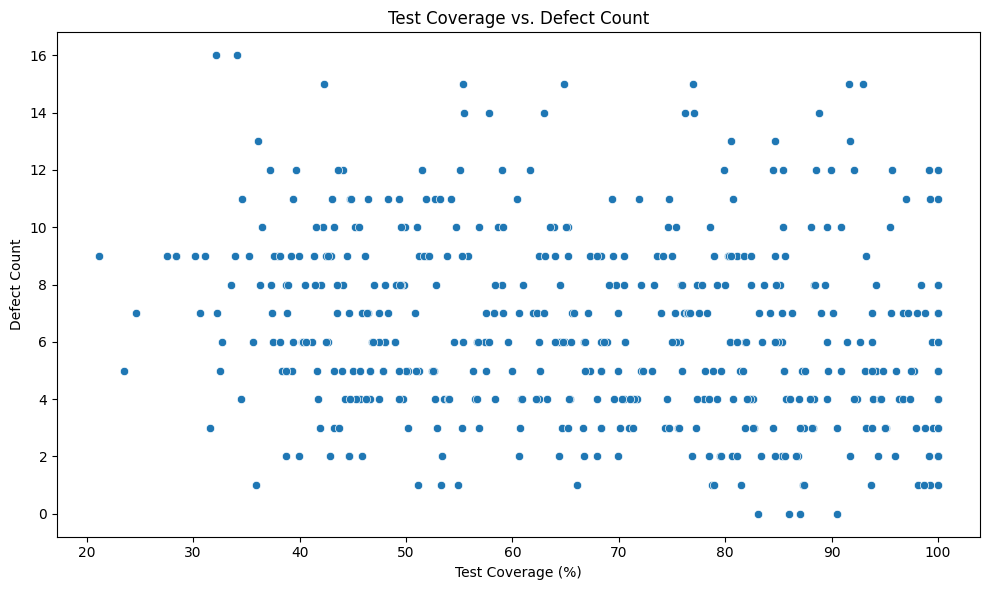

In [ ]:

# Calculate correlation between test coverage and defects
coverage_data = combined[
    ["test_coverage", "defect_count"]
].dropna()

coverage_correlation = coverage_data[
    "test_coverage"
].corr(coverage_data["defect_count"])

print(
    "Correlation between test coverage and defects:",
    round(coverage_correlation, 3)
)

# Visualize the relationship
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=coverage_data,
    x="test_coverage",
    y="defect_count"
)

plt.title("Test Coverage vs. Defect Count")
plt.xlabel("Test Coverage (%)")
plt.ylabel("Defect Count")
plt.tight_layout()
plt.show()


Analyze coupling vs. defects

Correlation between coupling and defects: 0.077


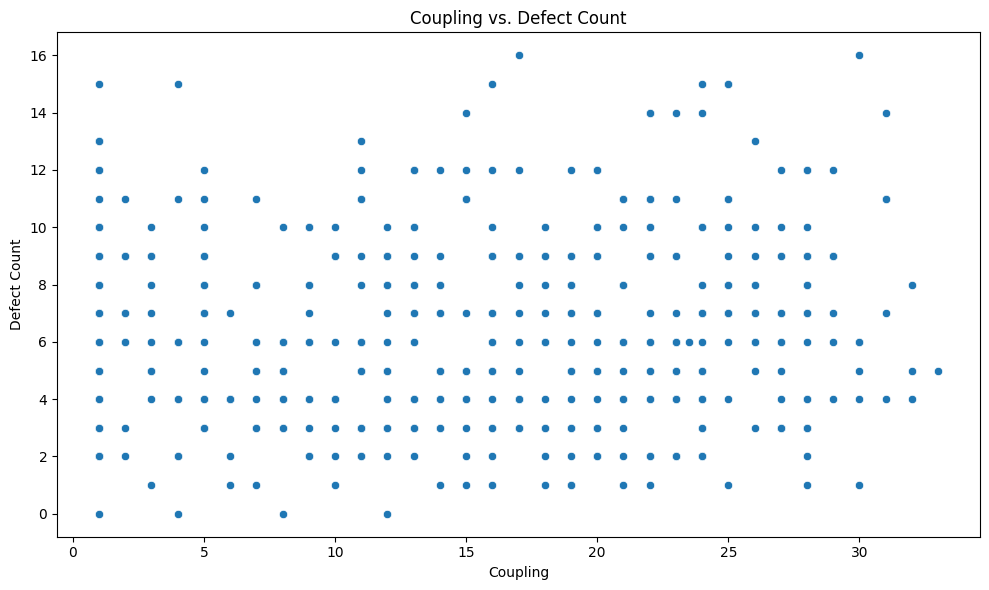

In [ ]:

# Calculate correlation between coupling and defects
coupling_data = combined[
    ["coupling", "defect_count"]
].dropna()

coupling_correlation = coupling_data[
    "coupling"
].corr(coupling_data["defect_count"])

print(
    "Correlation between coupling and defects:",
    round(coupling_correlation, 3)
)

# Visualize the relationship
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=coupling_data,
    x="coupling",
    y="defect_count"
)

plt.title("Coupling vs. Defect Count")
plt.xlabel("Coupling")
plt.ylabel("Defect Count")
plt.tight_layout()
plt.show()


Analyze changed lines vs. defects

Correlation between changed lines and defects: 0.023


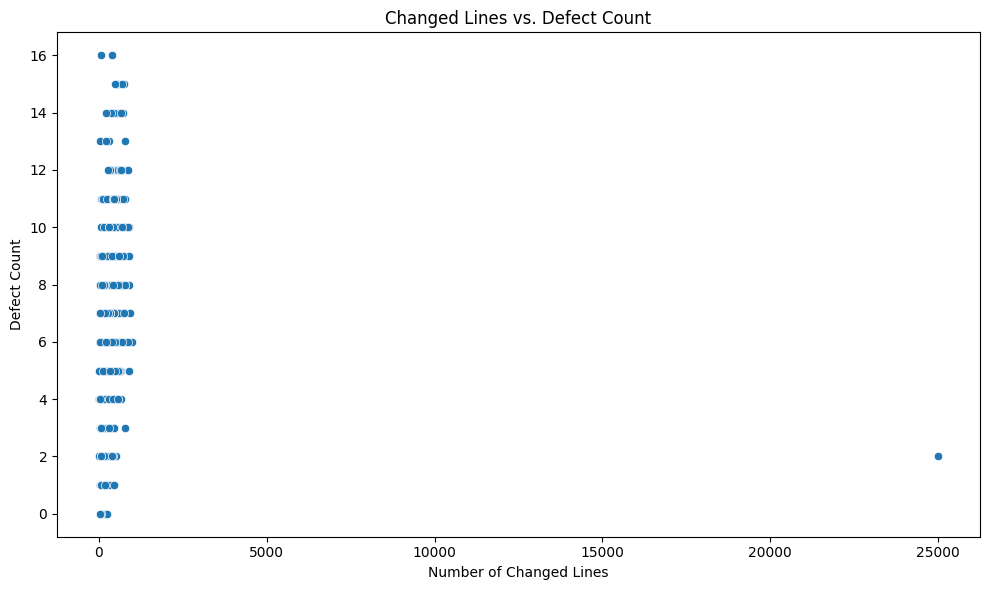

In [ ]:

# Calculate correlation between changed lines and defects
changed_lines_data = combined[
    ["changed_lines", "defect_count"]
].dropna()

changed_lines_correlation = changed_lines_data[
    "changed_lines"
].corr(changed_lines_data["defect_count"])

print(
    "Correlation between changed lines and defects:",
    round(changed_lines_correlation, 3)
)

# Visualize the relationship
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=changed_lines_data,
    x="changed_lines",
    y="defect_count"
)

plt.title("Changed Lines vs. Defect Count")
plt.xlabel("Number of Changed Lines")
plt.ylabel("Defect Count")
plt.tight_layout()
plt.show()


Check correlation without the extreme value

In [ ]:

# Exclude the extreme changed_lines value for comparison
normal_changes = combined[
    (combined["changed_lines"] <= 5000) &
    (combined["changed_lines"].notna()) &
    (combined["defect_count"].notna())
]

correlation_without_extreme = normal_changes[
    "changed_lines"
].corr(normal_changes["defect_count"])

print(
    "Correlation before excluding extreme value:",
    round(changed_lines_correlation, 3)
)

print(
    "Correlation after excluding extreme value:",
    round(correlation_without_extreme, 3)
)

print("Rows before filtering:", len(changed_lines_data))
print("Rows after filtering:", len(normal_changes))


Correlation before excluding extreme value: 0.023
Correlation after excluding extreme value: 0.437
Rows before filtering: 499
Rows after filtering: 498


Visualize the correlation matrix

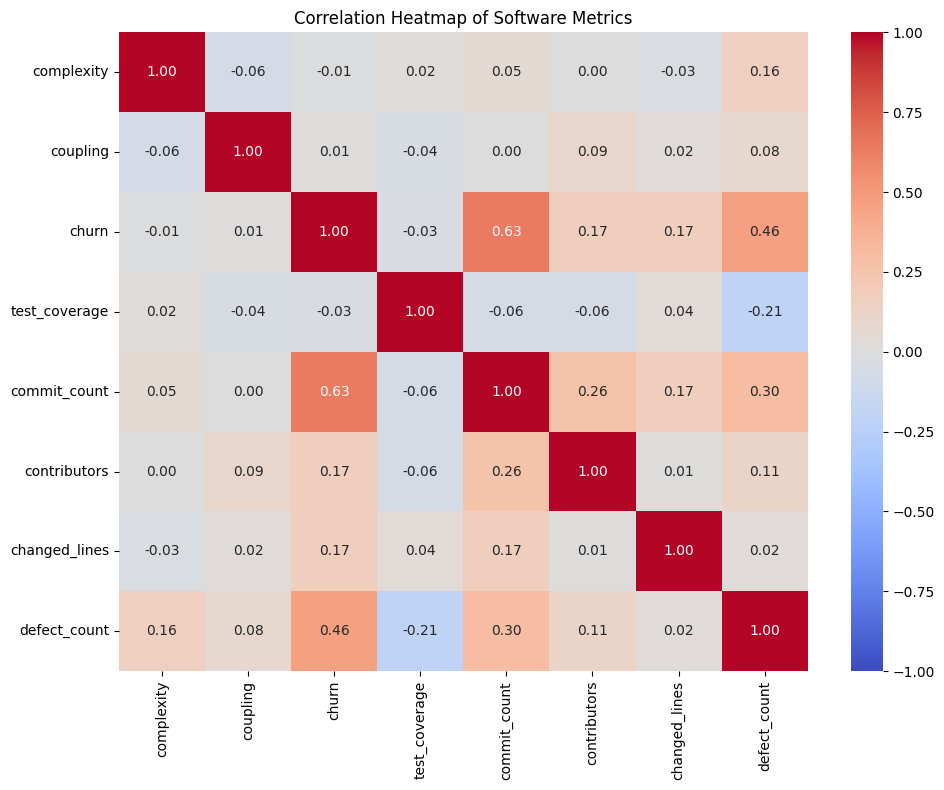

In [ ]:

# Select numeric software metrics and defect count
correlation_columns = [
    "complexity",
    "coupling",
    "churn",
    "test_coverage",
    "commit_count",
    "contributors",
    "changed_lines",
    "defect_count"
]

correlation_matrix = combined[
    correlation_columns
].corr()

# Display correlation heatmap
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Software Metrics")
plt.tight_layout()
plt.show()


Feature engineering

In [ ]:

# Create a copy for feature engineering
feature_data = combined.copy()

# Calculate defects per commit
feature_data["defects_per_commit"] = (
    feature_data["defect_count"] /
    feature_data["commit_count"].replace(0, np.nan)
)

# Display the new feature
display(
    feature_data[
        ["module", "release", "defect_count",
         "commit_count", "defects_per_commit"]
    ].head(10)
)

# Summary statistics
print("\nSummary of defects per commit:")
display(feature_data["defects_per_commit"].describe())


,module,release,defect_count,commit_count,defects_per_commit
0,MOD001,v1.0,8.0,15,0.533333
1,MOD001,v2.0,0.0,13,0.000000
2,MOD001,v3.0,8.0,2,4.000000
3,MOD001,v4.0,2.0,9,0.222222
4,MOD001,v5.0,4.0,9,0.444444
5,MOD002,v1.0,6.0,20,0.300000
6,MOD002,v2.0,12.0,13,0.923077
7,MOD002,v3.0,3.0,20,0.150000
8,MOD002,v4.0,6.0,10,0.600000
9,MOD002,v5.0,6.0,18,0.333333



Summary of defects per commit:


,defects_per_commit
count,499.000000
mean,0.565173
std,0.392697
min,0.000000
25%,0.333333
50%,0.500000
75%,0.714286
max,4.000000


Create a high-defect indicator

In [ ]:

# Calculate the median defect count
defect_median = feature_data["defect_count"].median()

print("Median defect count:", defect_median)

# Create a binary feature
feature_data["high_defect"] = (
    feature_data["defect_count"] > defect_median
).astype(int)

# Display sample records
display(
    feature_data[
        ["module", "release", "defect_count", "high_defect"]
    ].head(10)
)

# Count records in each category
print("\nHigh-defect category counts:")
display(feature_data["high_defect"].value_counts())


Median defect count: 6.0


,module,release,defect_count,high_defect
0,MOD001,v1.0,8.0,1
1,MOD001,v2.0,0.0,0
2,MOD001,v3.0,8.0,1
3,MOD001,v4.0,2.0,0
4,MOD001,v5.0,4.0,0
5,MOD002,v1.0,6.0,0
6,MOD002,v2.0,12.0,1
7,MOD002,v3.0,3.0,0
8,MOD002,v4.0,6.0,0
9,MOD002,v5.0,6.0,0



High-defect category counts:


,count
high_defect,
0,279
1,221


Encode categorical features

In [ ]:

# Inspect categorical columns
categorical_columns = ["language", "component", "severity"]

for column in categorical_columns:
    if column in feature_data.columns:
        print(f"\n{column}:")
        print(feature_data[column].value_counts(dropna=False))



language:
language
JavaScript    145
C++           140
Python        115
Java          100
Name: count, dtype: int64

component:
component
Notifications      125
Payments            95
Inventory           95
Reporting           70
Authentication      65
User Management     50
Name: count, dtype: int64

severity:
severity
Low         196
Medium      157
High        109
Critical     37
NaN           1
Name: count, dtype: int64


Apply the encoding

In [ ]:

# Create a separate copy
encoded_data = feature_data.copy()

# One-hot encode language and component
encoded_data = pd.get_dummies(
    encoded_data,
    columns=["language", "component"],
    dtype=int
)

# Ordinal encode severity, preserving missing values
severity_mapping = {
    "Low": 1,
    "Medium": 2,
    "High": 3,
    "Critical": 4
}

encoded_data["severity_encoded"] = (
    encoded_data["severity"].map(severity_mapping)
)

# Display the new encoded columns
new_columns = [
    column for column in encoded_data.columns
    if column.startswith("language_")
    or column.startswith("component_")
]

new_columns.append("severity_encoded")

display(encoded_data[new_columns].head(10))

print("\nEncoded dataframe shape:", encoded_data.shape)
print(
    "Missing severity values after encoding:",
    encoded_data["severity_encoded"].isna().sum()
)


,language_C++,language_Java,language_JavaScript,language_Python,component_Authentication,component_Inventory,component_Notifications,component_Payments,component_Reporting,component_User Management,severity_encoded
0,0,1,0,0,0,0,0,0,1,0,1.0
1,0,1,0,0,0,0,0,0,1,0,1.0
2,0,1,0,0,0,0,0,0,1,0,2.0
3,0,1,0,0,0,0,0,0,1,0,1.0
4,0,1,0,0,0,0,0,0,1,0,3.0
5,1,0,0,0,0,0,1,0,0,0,3.0
6,1,0,0,0,0,0,1,0,0,0,3.0
7,1,0,0,0,0,0,1,0,0,0,1.0
8,1,0,0,0,0,0,1,0,0,0,2.0
9,1,0,0,0,0,0,1,0,0,0,2.0



Encoded dataframe shape: (500, 28)
Missing severity values after encoding: 1


Identify useful features

In [ ]:

# Select numeric features for preliminary feature analysis
feature_columns = [
    "complexity",
    "coupling",
    "churn",
    "test_coverage",
    "commit_count",
    "contributors",
    "changed_lines",
    "defects_per_commit"
]

# Calculate correlation with the high_defect target
feature_correlations = (
    feature_data[feature_columns + ["high_defect"]]
    .corr(numeric_only=True)["high_defect"]
    .drop("high_defect")
    .sort_values(key=abs, ascending=False)
)

print("Correlation of features with high_defect:")
display(feature_correlations.to_frame("correlation"))


Correlation of features with high_defect:


,correlation
defects_per_commit,0.513073
churn,0.384037
commit_count,0.237362
test_coverage,-0.164175
complexity,0.133564
contributors,0.094638
coupling,0.051906
changed_lines,0.032950


Select candidate features

In [ ]:

# Candidate features without target leakage
candidate_features = [
    "complexity",
    "coupling",
    "churn",
    "test_coverage",
    "commit_count",
    "contributors",
    "changed_lines"
]

X = feature_data[candidate_features].copy()
y = feature_data["high_defect"].copy()

print("Candidate feature count:", len(candidate_features))
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nMissing values in candidate features:")
display(X.isna().sum())

print("\nTarget distribution:")
display(y.value_counts())


Candidate feature count: 7
Feature matrix shape: (500, 7)
Target shape: (500,)

Missing values in candidate features:


,0
complexity,1
coupling,1
churn,1
test_coverage,1
commit_count,0
contributors,0
changed_lines,0



Target distribution:


,count
high_defect,
0,279
1,221


Handle missing values in candidate features

In [ ]:

# Fill missing predictor values using each column's median
X_clean = X.fillna(X.median())

print("Missing values after imputation:")
display(X_clean.isna().sum())

print("\nClean feature matrix shape:", X_clean.shape)

# Confirm that the target has no missing values
print("\nMissing target values:", y.isna().sum())


Missing values after imputation:


,0
complexity,0
coupling,0
churn,0
test_coverage,0
commit_count,0
contributors,0
changed_lines,0



Clean feature matrix shape: (500, 7)

Missing target values: 0


Select important features using SelectKBest

In [ ]:

from sklearn.feature_selection import SelectKBest, chi2
from sklearn.preprocessing import MinMaxScaler

# Scale features to a non-negative range
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X_clean)

# Select the top 5 features
selector = SelectKBest(score_func=chi2, k=5)
selector.fit(X_scaled, y)

# Display feature scores
feature_scores = pd.DataFrame({
    "feature": candidate_features,
    "chi2_score": selector.scores_,
    "selected": selector.get_support()
}).sort_values("chi2_score", ascending=False)

display(feature_scores)


,feature,chi2_score,selected
2,churn,12.570362,True
4,commit_count,2.112724,True
3,test_coverage,1.520934,True
5,contributors,0.853635,True
0,complexity,0.375153,True
1,coupling,0.211005,False
6,changed_lines,0.075886,False


Visualize the feature scores

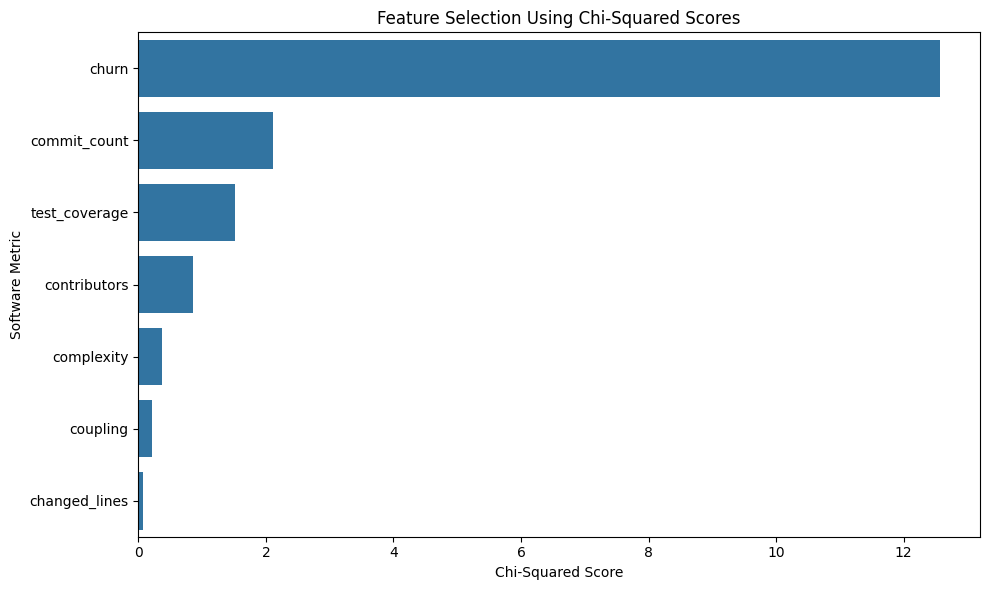

In [ ]:

# Sort features by chi-squared score
scores_plot = feature_scores.sort_values(
    "chi2_score", ascending=False
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=scores_plot,
    x="chi2_score",
    y="feature"
)

plt.title("Feature Selection Using Chi-Squared Scores")
plt.xlabel("Chi-Squared Score")
plt.ylabel("Software Metric")
plt.tight_layout()
plt.show()


Save your cleaned analysis dataset

In [ ]:

# Save the cleaned dataset with engineered features
feature_data.to_csv(
    "software_quality_eda_results.csv",
    index=False
)

print("Dataset saved successfully!")
print("Rows:", feature_data.shape[0])
print("Columns:", feature_data.shape[1])


Dataset saved successfully!
Rows: 500
Columns: 19
